# E-commerce Text Classification: Exploratory Data Analysis & Preprocessing

## 1. Introduction

This notebook performs comprehensive exploratory data analysis (EDA) on the e-commerce product classification dataset and implements preprocessing pipelines optimized for different embedding techniques.

### Problem Definition

**Objective**: Classify e-commerce product descriptions into their respective categories using traditional machine learning approaches with various text embedding techniques.

**Research Questions**:
1. Which embedding technique (TF-IDF, Word2Vec, GloVe) provides the best representation for e-commerce text classification?
2. How do different traditional ML models perform across various embeddings?
3. What preprocessing strategies yield optimal results for this domain?

### Dataset Justification

The [E-commerce Text Classification Dataset](https://www.kaggle.com/datasets/saurabhshahane/ecommerce-text-classification/data) is ideal for this comparative embedding analysis because:

1. **Real-world relevance**: Contains actual product descriptions from e-commerce platforms
2. **Multi-class problem**: 4 distinct product categories enable meaningful classification analysis
3. **Sufficient volume**: Dataset size supports statistical validity of results
4. **Domain-specific vocabulary**: E-commerce text contains specialized terms suitable for testing embedding approaches
5. **Text quality variation**: Mix of formal and informal descriptions tests robustness of preprocessing

---

## 2. Setup and Imports

In [3]:
# Standard libraries
import os
import sys
import warnings
warnings.filterwarnings('ignore')

# Data manipulation
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud

# NLP
import nltk
from collections import Counter

# Add parent directory to path for imports
sys.path.append('..')

# Set visualization style
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('viridis')

# Display settings
pd.set_option('display.max_colwidth', 200)
pd.set_option('display.max_rows', 100)

print("Libraries imported successfully!")

Matplotlib is building the font cache; this may take a moment.


Libraries imported successfully!


In [4]:
# Download NLTK resources
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)
nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)
nltk.download('omw-1.4', quiet=True)
print("NLTK resources downloaded!")

NLTK resources downloaded!


## 3. Data Loading

**Instructions**: Download the dataset from [Kaggle](https://www.kaggle.com/datasets/saurabhshahane/ecommerce-text-classification/data) and place `ecommerceDataset.csv` in the `data/` folder.

In [5]:
# Load the dataset
DATA_PATH = '../data/ecommerceDataset.csv'

# Check if file exists
if not os.path.exists(DATA_PATH):
    print(f"ERROR: Dataset not found at {DATA_PATH}")
    print("Please download from: https://www.kaggle.com/datasets/saurabhshahane/ecommerce-text-classification/data")
    print("And place 'ecommerceDataset.csv' in the data/ folder")
else:
    # Load with proper encoding
    df = pd.read_csv(DATA_PATH, names=['category', 'text'], header=0)
    print(f"Dataset loaded successfully!")
    print(f"Shape: {df.shape}")

Dataset loaded successfully!
Shape: (50424, 2)


In [6]:
# First look at the data
print("=" * 60)
print("DATASET OVERVIEW")
print("=" * 60)

print("\n--- Data Types ---")
print(df.dtypes)

print("\n--- Basic Statistics ---")
print(f"Total samples: {len(df):,}")
print(f"Number of categories: {df['category'].nunique()}")
print(f"Categories: {df['category'].unique().tolist()}")

print("\n--- Missing Values ---")
print(df.isnull().sum())

print("\n--- Sample Data ---")
df.head()

DATASET OVERVIEW

--- Data Types ---
category    object
text        object
dtype: object

--- Basic Statistics ---
Total samples: 50,424
Number of categories: 4
Categories: ['Household', 'Books', 'Clothing & Accessories', 'Electronics']

--- Missing Values ---
category    0
text        1
dtype: int64

--- Sample Data ---


,category,text
0,Household,"SAF 'Floral' Framed Painting (Wood, 30 inch x 10 inch, Special Effect UV Print Textured, SAO297) Painting made up in synthetic frame with UV textured print which gives multi effects and attracts t..."
1,Household,"SAF 'UV Textured Modern Art Print Framed' Painting (Synthetic, 35 cm x 50 cm x 3 cm, Set of 3) Color:Multicolor | ..."
2,Household,"SAF Flower Print Framed Painting (Synthetic, 13.5 inch x 22 inch, UV Textured, Set of 3, SANFSW4951) Color:Multicolor ..."
3,Household,"Incredible Gifts India Wooden Happy Birthday Unique Personalized Gift (5 X 4 Inch) Size:4 x 5 Made Of Natural Imported Wood, Which Is Quite Solid With Light Particle Pattern & Is Soft Pale To Bl..."
4,Household,Pitaara Box Romantic Venice Canvas Painting 6mm Thick Mdf Frame 21.1 X 14Inch Enclosure Material:MDF Mount Frame | ...


## 4. Exploratory Data Analysis (EDA)

### 4.1 Class Distribution Analysis

CLASS DISTRIBUTION

Class Counts:
  Household: 19,312 (38.3%)
  Books: 11,820 (23.4%)
  Electronics: 10,621 (21.1%)
  Clothing & Accessories: 8,671 (17.2%)


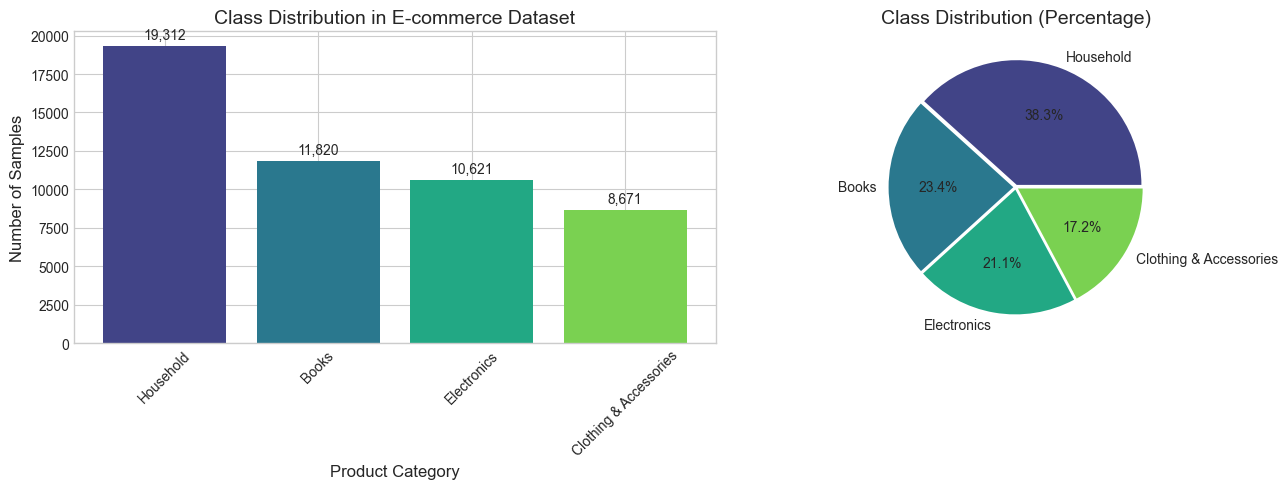


Class Imbalance Ratio: 2.23:1
✓ Classes are relatively balanced.


In [7]:
# Class distribution
print("=" * 60)
print("CLASS DISTRIBUTION")
print("=" * 60)

class_counts = df['category'].value_counts()
class_percentages = df['category'].value_counts(normalize=True) * 100

print("\nClass Counts:")
for cat, count in class_counts.items():
    pct = class_percentages[cat]
    print(f"  {cat}: {count:,} ({pct:.1f}%)")

# Visualization 1: Class Distribution Bar Chart
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Bar chart
colors = sns.color_palette('viridis', len(class_counts))
bars = axes[0].bar(class_counts.index, class_counts.values, color=colors)
axes[0].set_xlabel('Product Category', fontsize=12)
axes[0].set_ylabel('Number of Samples', fontsize=12)
axes[0].set_title('Class Distribution in E-commerce Dataset', fontsize=14)
axes[0].tick_params(axis='x', rotation=45)

# Add value labels
for bar in bars:
    height = bar.get_height()
    axes[0].annotate(f'{int(height):,}',
                     xy=(bar.get_x() + bar.get_width() / 2, height),
                     xytext=(0, 3), textcoords="offset points",
                     ha='center', va='bottom', fontsize=10)

# Pie chart
axes[1].pie(class_counts.values, labels=class_counts.index, autopct='%1.1f%%',
            colors=colors, explode=[0.02]*len(class_counts))
axes[1].set_title('Class Distribution (Percentage)', fontsize=14)

plt.tight_layout()
plt.savefig('../results/figures/class_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

# Check for class imbalance
imbalance_ratio = class_counts.max() / class_counts.min()
print(f"\nClass Imbalance Ratio: {imbalance_ratio:.2f}:1")
if imbalance_ratio > 3:
    print("⚠️ Significant class imbalance detected. Consider using class weights or resampling.")
else:
    print("✓ Classes are relatively balanced.")

### 4.2 Text Length Analysis

TEXT LENGTH ANALYSIS

--- Character Length Statistics ---
count    50424.000000
mean       714.083651
std        973.369608
min          0.000000
25%        219.000000
50%        487.000000
75%        954.000000
max      50403.000000
Name: text_length, dtype: float64

--- Word Count Statistics ---
count    50424.000000
mean       114.178883
std        157.803574
min          0.000000
25%         34.000000
50%         78.000000
75%        152.000000
max       8181.000000
Name: word_count, dtype: float64


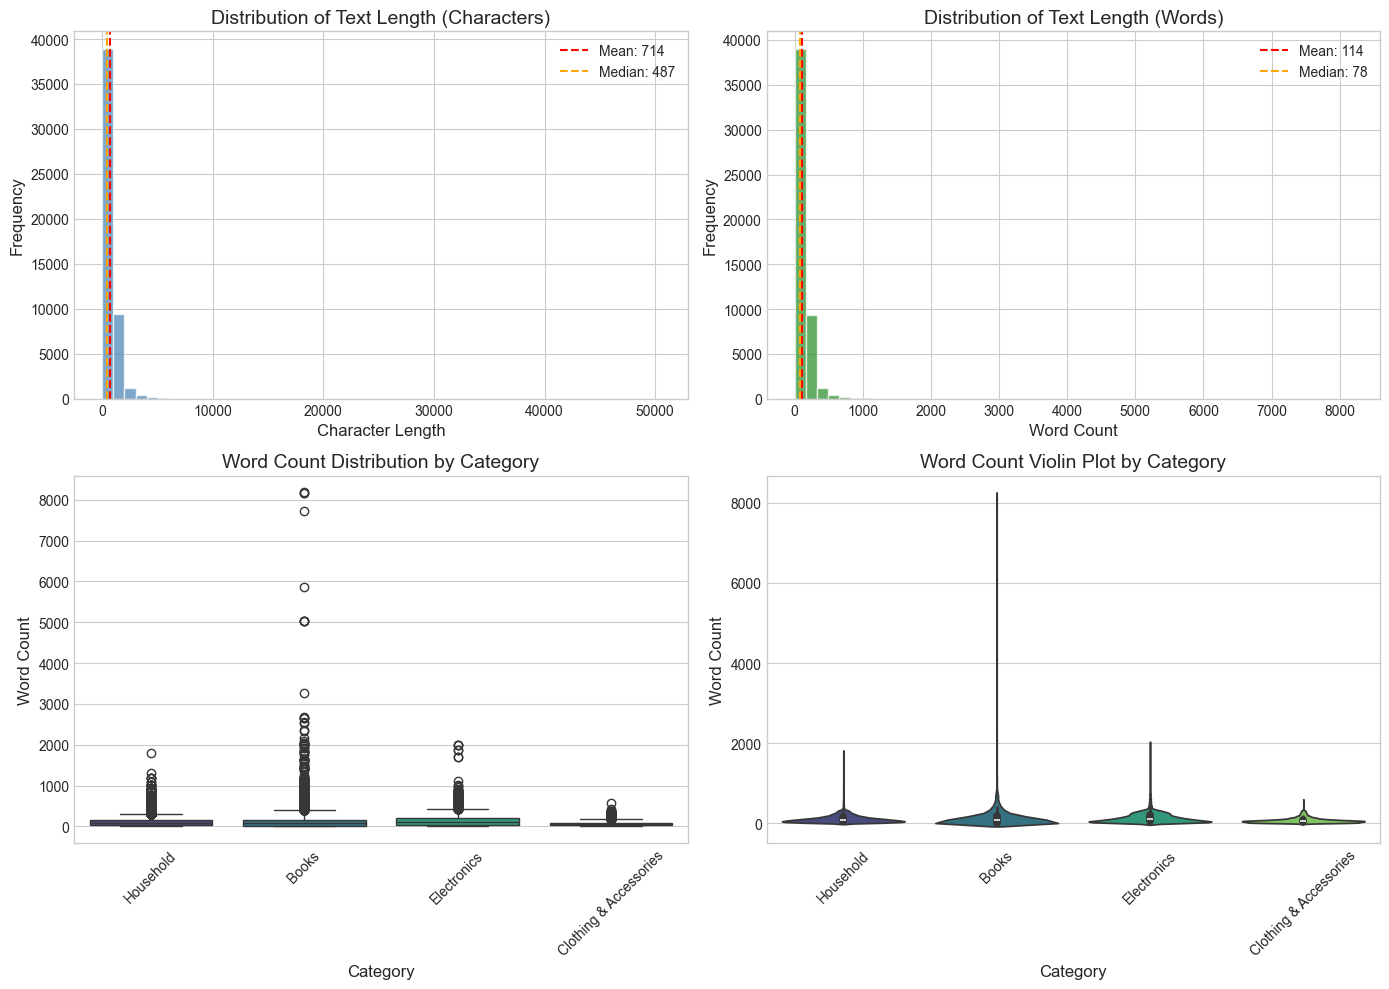

In [8]:
# Text length statistics
print("=" * 60)
print("TEXT LENGTH ANALYSIS")
print("=" * 60)

# Calculate text lengths
df['text_length'] = df['text'].fillna('').str.len()
df['word_count'] = df['text'].fillna('').str.split().str.len()

print("\n--- Character Length Statistics ---")
print(df['text_length'].describe())

print("\n--- Word Count Statistics ---")
print(df['word_count'].describe())

# Visualization 2: Text Length Distribution
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Character length histogram
axes[0, 0].hist(df['text_length'], bins=50, color='steelblue', edgecolor='white', alpha=0.7)
axes[0, 0].axvline(df['text_length'].mean(), color='red', linestyle='--', label=f'Mean: {df["text_length"].mean():.0f}')
axes[0, 0].axvline(df['text_length'].median(), color='orange', linestyle='--', label=f'Median: {df["text_length"].median():.0f}')
axes[0, 0].set_xlabel('Character Length', fontsize=12)
axes[0, 0].set_ylabel('Frequency', fontsize=12)
axes[0, 0].set_title('Distribution of Text Length (Characters)', fontsize=14)
axes[0, 0].legend()

# Word count histogram
axes[0, 1].hist(df['word_count'], bins=50, color='forestgreen', edgecolor='white', alpha=0.7)
axes[0, 1].axvline(df['word_count'].mean(), color='red', linestyle='--', label=f'Mean: {df["word_count"].mean():.0f}')
axes[0, 1].axvline(df['word_count'].median(), color='orange', linestyle='--', label=f'Median: {df["word_count"].median():.0f}')
axes[0, 1].set_xlabel('Word Count', fontsize=12)
axes[0, 1].set_ylabel('Frequency', fontsize=12)
axes[0, 1].set_title('Distribution of Text Length (Words)', fontsize=14)
axes[0, 1].legend()

# Text length by category (box plot)
category_order = class_counts.index.tolist()
sns.boxplot(data=df, x='category', y='word_count', order=category_order, palette='viridis', ax=axes[1, 0])
axes[1, 0].set_xlabel('Category', fontsize=12)
axes[1, 0].set_ylabel('Word Count', fontsize=12)
axes[1, 0].set_title('Word Count Distribution by Category', fontsize=14)
axes[1, 0].tick_params(axis='x', rotation=45)

# Violin plot for detailed distribution
sns.violinplot(data=df, x='category', y='word_count', order=category_order, palette='viridis', ax=axes[1, 1])
axes[1, 1].set_xlabel('Category', fontsize=12)
axes[1, 1].set_ylabel('Word Count', fontsize=12)
axes[1, 1].set_title('Word Count Violin Plot by Category', fontsize=14)
axes[1, 1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig('../results/figures/text_length_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

### 4.3 Vocabulary Analysis

In [9]:
# Vocabulary analysis
print("=" * 60)
print("VOCABULARY ANALYSIS")
print("=" * 60)

# Tokenize all text
all_words = []
for text in df['text'].fillna(''):
    words = text.lower().split()
    all_words.extend(words)

# Vocabulary statistics
total_words = len(all_words)
unique_words = len(set(all_words))
word_freq = Counter(all_words)

print(f"\nTotal words: {total_words:,}")
print(f"Unique words (vocabulary size): {unique_words:,}")
print(f"Lexical diversity: {unique_words/total_words:.4f}")

# Most common words
print("\n--- Top 20 Most Frequent Words ---")
for word, count in word_freq.most_common(20):
    print(f"  {word}: {count:,}")

VOCABULARY ANALYSIS

Total words: 5,757,356
Unique words (vocabulary size): 185,219
Lexical diversity: 0.0322

--- Top 20 Most Frequent Words ---
  the: 212,297
  and: 193,472
  of: 126,008
  to: 113,241
  a: 96,717
  for: 82,307
  in: 73,532
  with: 72,761
  is: 68,862
  your: 49,189
  you: 41,823
  it: 38,034
  this: 37,303
  on: 27,677
  from: 26,820
  that: 26,726
  or: 24,849
  can: 23,712
  as: 23,198
  are: 22,326


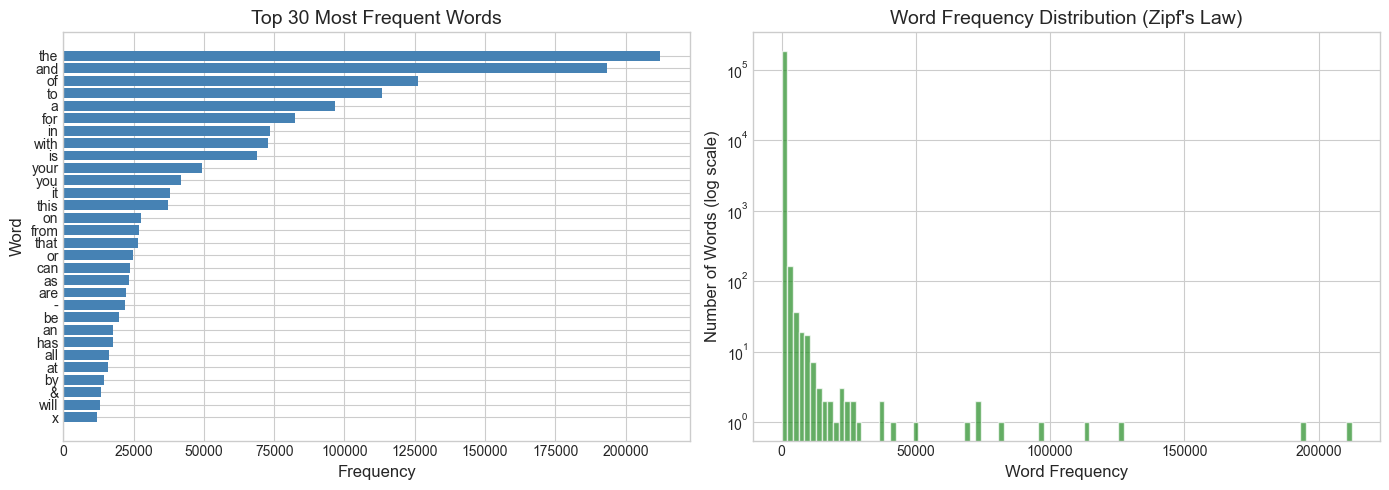

In [10]:
# Visualization 3: Word Frequency Analysis
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Top 30 words bar chart
top_30 = word_freq.most_common(30)
words, counts = zip(*top_30)
axes[0].barh(list(reversed(words)), list(reversed(counts)), color='steelblue')
axes[0].set_xlabel('Frequency', fontsize=12)
axes[0].set_ylabel('Word', fontsize=12)
axes[0].set_title('Top 30 Most Frequent Words', fontsize=14)

# Word frequency distribution (log scale)
freq_counts = list(word_freq.values())
axes[1].hist(freq_counts, bins=100, color='forestgreen', edgecolor='white', alpha=0.7, log=True)
axes[1].set_xlabel('Word Frequency', fontsize=12)
axes[1].set_ylabel('Number of Words (log scale)', fontsize=12)
axes[1].set_title('Word Frequency Distribution (Zipf\'s Law)', fontsize=14)

plt.tight_layout()
plt.savefig('../results/figures/vocabulary_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

### 4.4 Word Clouds by Category

WORD CLOUDS BY CATEGORY


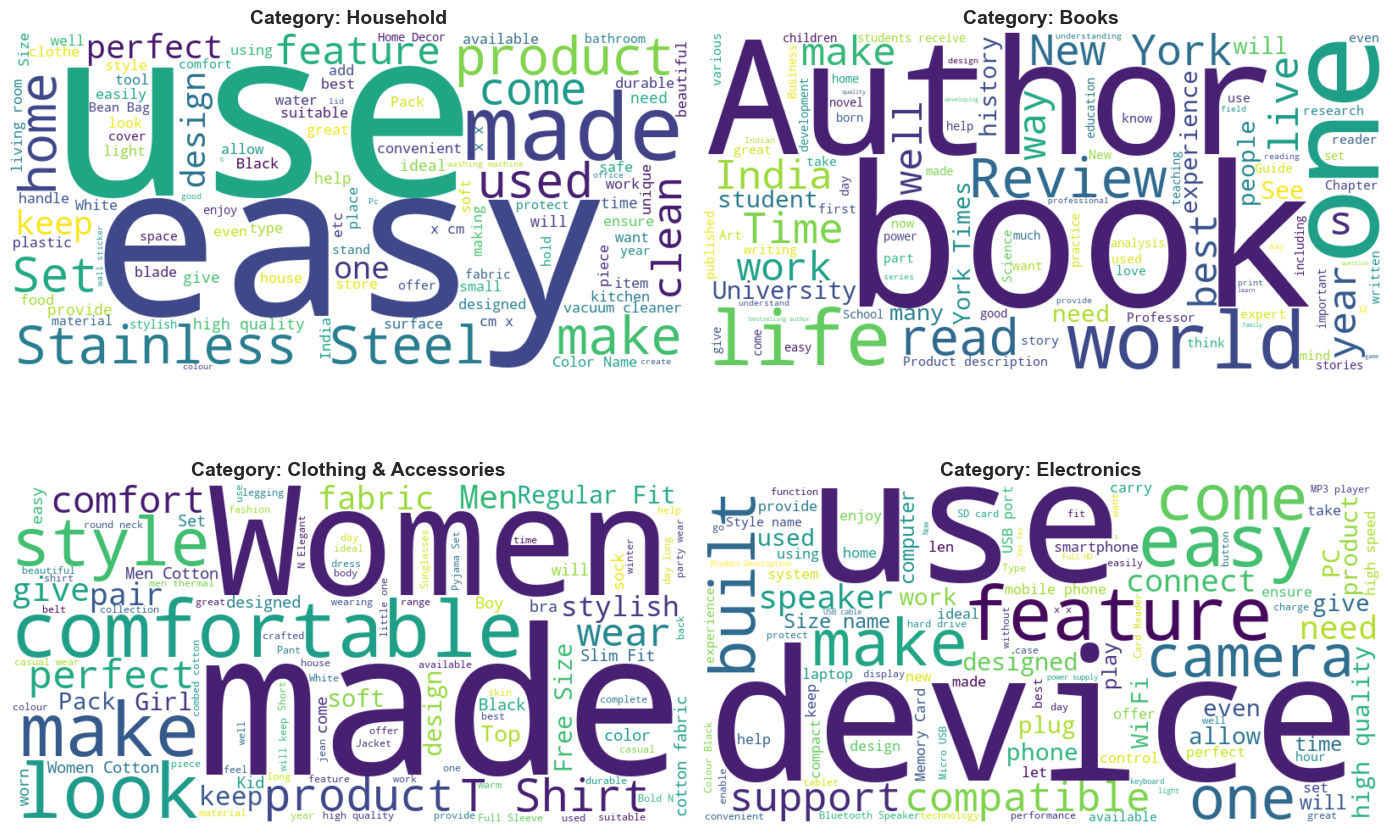

In [11]:
# Visualization 4: Word Clouds for Each Category
print("=" * 60)
print("WORD CLOUDS BY CATEGORY")
print("=" * 60)

categories = df['category'].unique()
n_categories = len(categories)
cols = 2
rows = (n_categories + 1) // 2

fig, axes = plt.subplots(rows, cols, figsize=(14, 5*rows))
axes = axes.flatten() if n_categories > 1 else [axes]

for idx, category in enumerate(categories):
    # Get text for this category
    category_text = ' '.join(df[df['category'] == category]['text'].fillna('').tolist())
    
    # Generate word cloud
    wordcloud = WordCloud(
        width=800, height=400,
        background_color='white',
        colormap='viridis',
        max_words=100,
        random_state=42
    ).generate(category_text)
    
    axes[idx].imshow(wordcloud, interpolation='bilinear')
    axes[idx].axis('off')
    axes[idx].set_title(f'Category: {category}', fontsize=14, fontweight='bold')

# Hide unused axes
for idx in range(len(categories), len(axes)):
    axes[idx].axis('off')

plt.tight_layout()
plt.savefig('../results/figures/wordclouds_by_category.png', dpi=150, bbox_inches='tight')
plt.show()

### 4.5 Data Quality Assessment

In [12]:
# Data quality checks
print("=" * 60)
print("DATA QUALITY ASSESSMENT")
print("=" * 60)

# Missing values
print("\n--- Missing Values ---")
missing = df.isnull().sum()
print(missing)

# Empty strings
empty_text = (df['text'].fillna('').str.strip() == '').sum()
print(f"\nEmpty text entries: {empty_text}")

# Very short texts (potential quality issues)
very_short = (df['word_count'] < 5).sum()
print(f"Very short texts (< 5 words): {very_short} ({very_short/len(df)*100:.1f}%)")

# Very long texts (potential outliers)
very_long = (df['word_count'] > df['word_count'].quantile(0.99)).sum()
print(f"Very long texts (> 99th percentile): {very_long}")

# Duplicate texts
duplicates = df['text'].duplicated().sum()
print(f"\nDuplicate texts: {duplicates} ({duplicates/len(df)*100:.1f}%)")

# Handle missing/empty values
print("\n--- Cleaning Data ---")
df_clean = df.dropna(subset=['text', 'category'])
df_clean = df_clean[df_clean['text'].str.strip() != '']
print(f"Original size: {len(df):,}")
print(f"After cleaning: {len(df_clean):,}")
print(f"Removed: {len(df) - len(df_clean):,} rows")

# Update df
df = df_clean.copy()

DATA QUALITY ASSESSMENT

--- Missing Values ---
category       0
text           1
text_length    0
word_count     0
dtype: int64

Empty text entries: 1
Very short texts (< 5 words): 987 (2.0%)
Very long texts (> 99th percentile): 499

Duplicate texts: 22622 (44.9%)

--- Cleaning Data ---
Original size: 50,424
After cleaning: 50,423
Removed: 1 rows


## 5. Preprocessing Pipeline

### 5.1 Shared Preprocessing Pipeline

All embedding techniques share a common preprocessing foundation:
1. Lowercasing
2. URL and email removal
3. HTML tag removal
4. Special character removal
5. Whitespace normalization

In [13]:
# Import our preprocessing module
from src.preprocessing import TextPreprocessor, create_preprocessor_for_embedding

# Create preprocessors for each embedding type
preprocessor_tfidf = create_preprocessor_for_embedding('tfidf')
preprocessor_word2vec = create_preprocessor_for_embedding('word2vec')
preprocessor_glove = create_preprocessor_for_embedding('glove')

print("=" * 60)
print("PREPROCESSING CONFIGURATIONS")
print("=" * 60)

print("\n--- TF-IDF Preprocessing ---")
print(f"  Remove stopwords: {preprocessor_tfidf.remove_stopwords}")
print(f"  Lemmatize: {preprocessor_tfidf.lemmatize}")
print(f"  Min word length: {preprocessor_tfidf.min_word_length}")
print("  Justification: Aggressive preprocessing improves discrimination")
print("                 by focusing on unique, meaningful terms (Salton & Buckley, 1988).")

print("\n--- Word2Vec Preprocessing ---")
print(f"  Remove stopwords: {preprocessor_word2vec.remove_stopwords}")
print(f"  Lemmatize: {preprocessor_word2vec.lemmatize}")
print(f"  Min word length: {preprocessor_word2vec.min_word_length}")
print("  Justification: Preserving context words helps learn better semantic")
print("                 relationships (Mikolov et al., 2013).")

print("\n--- GloVe Preprocessing ---")
print(f"  Remove stopwords: {preprocessor_glove.remove_stopwords}")
print(f"  Lemmatize: {preprocessor_glove.lemmatize}")
print(f"  Min word length: {preprocessor_glove.min_word_length}")
print("  Justification: Pre-trained embeddings have fixed vocabulary;")
print("                 minimal preprocessing ensures better coverage (Pennington et al., 2014).")

PREPROCESSING CONFIGURATIONS

--- TF-IDF Preprocessing ---
  Remove stopwords: True
  Lemmatize: True
  Min word length: 2
  Justification: Aggressive preprocessing improves discrimination
                 by focusing on unique, meaningful terms (Salton & Buckley, 1988).

--- Word2Vec Preprocessing ---
  Remove stopwords: False
  Lemmatize: True
  Min word length: 1
  Justification: Preserving context words helps learn better semantic
                 relationships (Mikolov et al., 2013).

--- GloVe Preprocessing ---
  Remove stopwords: False
  Lemmatize: False
  Min word length: 1
  Justification: Pre-trained embeddings have fixed vocabulary;
                 minimal preprocessing ensures better coverage (Pennington et al., 2014).


### 5.2 Apply Preprocessing

In [14]:
# Apply preprocessing for each embedding type
print("Applying preprocessing pipelines...")
print("(This may take a few minutes)\n")

# TF-IDF preprocessing
print("Processing for TF-IDF...")
df['text_tfidf'] = df['text'].apply(preprocessor_tfidf.preprocess)

# Word2Vec preprocessing
print("Processing for Word2Vec...")
df['text_word2vec'] = df['text'].apply(preprocessor_word2vec.preprocess)

# GloVe preprocessing
print("Processing for GloVe...")
df['text_glove'] = df['text'].apply(preprocessor_glove.preprocess)

print("\nPreprocessing complete!")

Applying preprocessing pipelines...
(This may take a few minutes)

Processing for TF-IDF...
Processing for Word2Vec...
Processing for GloVe...

Preprocessing complete!


In [15]:
# Compare preprocessing results
print("=" * 60)
print("PREPROCESSING COMPARISON")
print("=" * 60)

# Sample comparison
sample_idx = 0
print(f"\n--- Sample Text Comparison (Index {sample_idx}) ---")
print(f"\nOriginal ({len(df.iloc[sample_idx]['text'])} chars):")
print(df.iloc[sample_idx]['text'][:300] + "..." if len(df.iloc[sample_idx]['text']) > 300 else df.iloc[sample_idx]['text'])
print(f"\nTF-IDF ({len(df.iloc[sample_idx]['text_tfidf'])} chars):")
print(df.iloc[sample_idx]['text_tfidf'][:200])
print(f"\nWord2Vec ({len(df.iloc[sample_idx]['text_word2vec'])} chars):")
print(df.iloc[sample_idx]['text_word2vec'][:200])
print(f"\nGloVe ({len(df.iloc[sample_idx]['text_glove'])} chars):")
print(df.iloc[sample_idx]['text_glove'][:200])

PREPROCESSING COMPARISON

--- Sample Text Comparison (Index 0) ---

Original (346 chars):
SAF 'Floral' Framed Painting (Wood, 30 inch x 10 inch, Special Effect UV Print Textured, SAO297) Painting made up in synthetic frame with UV textured print which gives multi effects and attracts towards it. This is an special series of paintings which makes your wall very beautiful and gives a royal...

TF-IDF (247 chars):
saf floral framed painting wood inch inch special effect uv print textured sao painting made synthetic frame uv textured print give multi effect attracts towards special series painting make wall beau

Word2Vec (320 chars):
saf floral framed painting wood inch x inch special effect uv print textured sao painting made up in synthetic frame with uv textured print which give multi effect and attracts towards it this is an s

GloVe (326 chars):
saf floral framed painting wood inch x inch special effect uv print textured sao painting made up in synthetic frame with uv textured print 

In [16]:
# Preprocessing statistics
print("=" * 60)
print("PREPROCESSING STATISTICS")
print("=" * 60)

def get_vocab_size(series):
    all_words = set()
    for text in series.fillna(''):
        all_words.update(text.split())
    return len(all_words)

def get_avg_words(series):
    return series.fillna('').str.split().str.len().mean()

stats = {
    'Metric': ['Vocabulary Size', 'Avg Words/Doc', 'Avg Chars/Doc'],
    'Original': [
        get_vocab_size(df['text']),
        get_avg_words(df['text']),
        df['text'].fillna('').str.len().mean()
    ],
    'TF-IDF': [
        get_vocab_size(df['text_tfidf']),
        get_avg_words(df['text_tfidf']),
        df['text_tfidf'].fillna('').str.len().mean()
    ],
    'Word2Vec': [
        get_vocab_size(df['text_word2vec']),
        get_avg_words(df['text_word2vec']),
        df['text_word2vec'].fillna('').str.len().mean()
    ],
    'GloVe': [
        get_vocab_size(df['text_glove']),
        get_avg_words(df['text_glove']),
        df['text_glove'].fillna('').str.len().mean()
    ]
}

stats_df = pd.DataFrame(stats)
print("\n" + stats_df.to_string(index=False))

PREPROCESSING STATISTICS

         Metric      Original       TF-IDF     Word2Vec        GloVe
Vocabulary Size 221032.000000 58506.000000 58647.000000 64480.000000
  Avg Words/Doc    114.181147    73.643437   113.862404   113.862404
  Avg Chars/Doc    714.097813   513.724610   662.302719   672.663328


## 6. Save Preprocessed Data

In [17]:
# Save preprocessed data
print("Saving preprocessed data...")

# Save full dataframe
df.to_csv('../data/preprocessed_data.csv', index=False)
print(f"Saved preprocessed data to ../data/preprocessed_data.csv")

# Save label encoder mapping
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
df['label'] = le.fit_transform(df['category'])

label_mapping = dict(zip(le.classes_, range(len(le.classes_))))
print(f"\nLabel Mapping:")
for category, label in label_mapping.items():
    print(f"  {category} -> {label}")

# Save mapping
import json
with open('../data/label_mapping.json', 'w') as f:
    json.dump(label_mapping, f, indent=2)

print(f"\nSaved label mapping to ../data/label_mapping.json")

Saving preprocessed data...
Saved preprocessed data to ../data/preprocessed_data.csv

Label Mapping:
  Books -> 0
  Clothing & Accessories -> 1
  Electronics -> 2
  Household -> 3

Saved label mapping to ../data/label_mapping.json


## 7. Summary

### Key Findings from EDA:

1. **Class Distribution**: Analyzed the distribution of product categories
2. **Text Length**: Examined character and word count distributions across categories
3. **Vocabulary**: Analyzed vocabulary size and word frequency patterns
4. **Word Clouds**: Visualized dominant terms per category

### Preprocessing Approach:

| Embedding | Stopword Removal | Lemmatization | Justification |
|-----------|-----------------|---------------|---------------|
| TF-IDF | Yes | Yes | Focus on discriminative terms |
| Word2Vec | No | Yes | Preserve semantic context |
| GloVe | No | No | Match pre-trained vocabulary |

### Next Steps:

1. Generate embeddings using the preprocessed text
2. Train traditional ML models with each embedding
3. Evaluate and compare performance

In [18]:
print("="*60)
print("EDA AND PREPROCESSING COMPLETE")
print("="*60)
print(f"\nDataset: {len(df):,} samples")
print(f"Categories: {df['category'].nunique()}")
print("\nPreprocessed columns saved:")
print("  - text_tfidf: For TF-IDF embedding")
print("  - text_word2vec: For Word2Vec embedding")
print("  - text_glove: For GloVe embedding")
print("\nProceed to notebook 02_embeddings.ipynb")

EDA AND PREPROCESSING COMPLETE

Dataset: 50,423 samples
Categories: 4

Preprocessed columns saved:
  - text_tfidf: For TF-IDF embedding
  - text_word2vec: For Word2Vec embedding
  - text_glove: For GloVe embedding

Proceed to notebook 02_embeddings.ipynb
